# 03d · Interpretable-by-design baseline vs the LLM and the pruned circuit

Three systems on dataset **v2**:

| system | how it answers | size |
|---|---|---|
| **Qwen (full)** | d > 0 → "Yes" | 7.6 B parameters |
| **pruned circuit** (ACDC v3b, τ = 0, found on v2) | answers **alone**: edges outside the circuit get the dataset mean (as in 02e); d > 0 → "Yes" | 8147 edges (uses almost all parameters) |
| **rule**: situation classifier + phrase classifier + comparison | A · VADER, B · DistilBERT-SST-2, C · MiniLM + logistic regression | ~0 / 67 M / 22 M |

Two rules: **disagree** (sarcastic if the two sentiments disagree, in either direction) and **directional**
(only positive phrase + unpleasant situation). They differ only on **Q = pleasant situation + negative phrase**.

**Caveats:** the rule gets the situation and the phrase **already separated** (from the dataset); it ignores the
sentence frame, and the 140 situations are the same in every group, so for the rule the real generalisation test
is the **new phrases**. C is trained on our labels (every item predicted by a model that did not see it).

Parts: 0 · reliability of the classifiers, 1 · main table, 2 · agreement prompt by prompt, 3 · shared errors,
4 · the condition Q, 5 · correlation of the continuous scores, 6 · your own sentences.

**Runtime:** L4 / A100 ≈ 20–40 min (Qwen + circuit on 3640 prompts); the classifiers take a few minutes.
Needs the circuit of 02d on Drive (`02_acdc/<model>_data-v2/v3b/acdc_mask_tau0.0.npy`).

## Setup

In [1]:
# Get (or update) the code from GitHub
import os, sys
REPO = "https://github.com/vasilis-pantzos/sarcasm-proposal.git"
ROOT = "/content/sarcasm-proposal"
if not os.path.exists(ROOT):
    !git clone -q {REPO} {ROOT}
else:
    !git -C {ROOT} pull -q
os.chdir(ROOT)
sys.path.insert(0, ROOT)
%pip install -q -U accelerate bitsandbytes vaderSentiment sentence-transformers

In [2]:
import os, json, time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display
from src.model import load_model, model_info, DEV_MODEL, MAIN_MODEL
from src.prompts import load_dataset, encode, chat_text, data_tag
from src.eap import build_graph
from src.standalone import MeanReference, StandaloneEvaluator, standalone_d
from src.baseline import (vader_p, vader_words, sst2_p, minilm_embed, oof_p, fit_logreg, apply_rules, compare,
                          triple_acc)
from src.utils import mount_drive, results_dir, cached, set_seed

# ---------------- settings ----------------
MODEL = MAIN_MODEL          # DEV_MODEL (3B) for quick tests
DATA = "v2"
CIRCUIT = "v3b/acdc_mask_tau0.0.npy"   # the final pruned circuit (02d)
# ------------------------------------------
TAG_MODEL = MODEL.split("/")[-1]
TAG = TAG_MODEL + data_tag(DATA)
SUB = f"03d_baseline/{TAG}"
mount_drive()
print("results go to:", results_dir(SUB))
set_seed(0)

Mounted at /content/drive
results go to: /content/drive/MyDrive/sarcasm/03d_baseline/Qwen2.5-7B-Instruct_data-v2


## Data: P, S, N and the fourth condition Q

In [3]:
df = load_dataset(DATA).sort_values(["split", "triple_id", "condition"]).reset_index(drop=True)
df["group"] = [s if s == "discovery" else f"heldout ({t})" for s, t in zip(df.split, df.heldout_type)]
GROUPS = ["discovery", "heldout (phrase)", "heldout (frame)"]

# Q: P's sentence with N's phrase (pleasant situation + negative phrase), as in 03a
q_rows = []
for tid, g in df.groupby("triple_id"):
    r = g.set_index("condition")
    P, N = r.loc["P"], r.loc["N"]
    q_rows.append(dict(triple_id=tid, condition="Q", text=P.text[: -len(P.frame)] + N.frame, situation=P.situation,
                       situation_type=P.situation_type, frame=N.frame, frame_type=N.frame_type, group=P.group,
                       sarcastic=np.nan))
template = df.prompt.iloc[0].replace(df.text.iloc[0], "{}")
QD = pd.DataFrame(q_rows)
QD["prompt"] = [template.format(t) for t in QD.text]
D4 = pd.concat([df[QD.columns], QD], ignore_index=True)
D4["truth"] = D4.condition == "S"
PSN = (D4.condition != "Q").values
print({g: int((D4.group == g).sum()) for g in GROUPS}, "prompts (P, S, N, Q)")
print("Q example:", QD.text.iloc[0])

{'discovery': 2520, 'heldout (phrase)': 840, 'heldout (frame)': 280} prompts (P, S, N, Q)
Q example: The highlight of my day: relaxing on the beach. Ugh, so annoying.


## 0 · Reliability of the classifiers

Each classifier on the **unique** situations (140, pleasant / unpleasant) and phrases (36 discovery + 12 new,
positive / negative). C: situations by 5-fold cross-validation over all 140; discovery phrases by 5-fold over the
36; new phrases by a model trained on all 36 discovery phrases.

In [4]:
SIT = df[["situation", "situation_type"]].drop_duplicates("situation").reset_index(drop=True)
PHR = df[["frame", "frame_type", "group"]].copy()
PHR["new"] = PHR.group == "heldout (phrase)"
PHR = PHR.groupby(["frame", "frame_type"], as_index=False).new.max()
y_sit = (SIT.situation_type == "pleasant").values
y_phr = (PHR.frame_type == "positive").values
print(len(SIT), "situations,", len(PHR), "phrases (", int(PHR.new.sum()), "new )")

def run_classifiers():
    E_sit, E_phr = minilm_embed(SIT.situation), minilm_embed(PHR.frame)
    return {
        "A · VADER": (vader_p(SIT.situation), vader_p(PHR.frame)),
        "B · SST-2": (sst2_p(SIT.situation), sst2_p(PHR.frame)),
        "C · MiniLM": (oof_p(E_sit, y_sit, np.ones(len(SIT), bool)), oof_p(E_phr, y_phr, ~PHR.new.values)),
    }

t0 = time.time()
CLS = cached("classifier_p", run_classifiers, sub=SUB)
print(f"{time.time() - t0:.0f} s")
CLASSIFIERS = list(CLS)

rows = []
for c, (ps, pp) in CLS.items():
    rows.append({"classifier": c,
                 "situations": ((ps > 0.5) == y_sit).mean(),
                 "  pleasant": ((ps > 0.5) == y_sit)[y_sit].mean(),
                 "  unpleasant": ((ps > 0.5) == y_sit)[~y_sit].mean(),
                 "phrases (known)": ((pp > 0.5) == y_phr)[~PHR.new].mean(),
                 "phrases (new)": ((pp > 0.5) == y_phr)[PHR.new].mean()})
REL = pd.DataFrame(rows).set_index("classifier")
display(REL.round(3))
print("VADER: situations with no sentiment word (compound = 0):", f"{(np.abs(CLS['A · VADER'][0] - 0.5) < 1e-9).mean():.0%}")

140 situations, 48 phrases ( 12 new )


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (13 outputs left out)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[saved]  /content/drive/MyDrive/sarcasm/03d_baseline/Qwen2.5-7B-Instruct_data-v2/classifier_p.pt
37 s


,situations,pleasant,unpleasant,phrases (known),phrases (new)
classifier,,,,,
A · VADER,0.750,0.529,0.971,0.861,0.750
B · SST-2,0.829,0.843,0.814,0.972,0.833
C · MiniLM,0.757,0.800,0.714,0.972,1.000


VADER: situations with no sentiment word (compound = 0): 51%


In [5]:
# the mistakes of every classifier
for c, (ps, pp) in CLS.items():
    ws = SIT[(ps > 0.5) != y_sit].assign(p=ps[(ps > 0.5) != y_sit])
    wp = PHR[(pp > 0.5) != y_phr].assign(p=pp[(pp > 0.5) != y_phr])
    print(f"\n=== {c}: {len(ws)} situations, {len(wp)} phrases wrong")
    print("situations:", "; ".join(f"{s} ({t[:4]}, p={p:.2f})" for s, t, p in ws[["situation", "situation_type", "p"]].values[:25]))
    print("phrases:   ", "; ".join(f"{s} ({t[:3]}{', new' if n else ''}, p={p:.2f})" for s, t, n, p in wp[["frame", "frame_type", "new", "p"]].values))
print("\nexample of a VADER explanation:", "Nothing could be better.", vader_words("Nothing could be better."))


=== A · VADER: 35 situations, 8 phrases wrong
situations: getting a day off (plea, p=0.50); sleeping in late (plea, p=0.50); a quiet evening at home (plea, p=0.50); finding a parking spot (plea, p=0.50); a hot shower (plea, p=0.50); a fast internet connection (plea, p=0.50); my train arriving early (plea, p=0.50); passing the exam (plea, p=0.50); hot coffee in the morning (plea, p=0.50); a short queue (plea, p=0.50); my phone working (plea, p=0.50); finding my lost keys (plea, p=0.34); getting a raise (plea, p=0.50); a fast checkout (plea, p=0.50); a long nap (plea, p=0.50); my package arriving early (plea, p=0.50); a cozy fire (plea, p=0.33); a hot meal (plea, p=0.50); a quiet night (plea, p=0.50); an early train (plea, p=0.50); a surprise audit (unpl, p=0.64); a picnic in the sun (plea, p=0.50); a quick commute (plea, p=0.50); a quiet bus ride (plea, p=0.50); a new phone (plea, p=0.50)
phrases:    Exactly what I wanted. (pos, p=0.50); Great, just what I feared. (neg, new, p=0.61); I

## The rule on every prompt

In [6]:
sit_idx = D4.situation.map({s: i for i, s in enumerate(SIT.situation)}).values
phr_idx = D4.frame.map({s: i for i, s in enumerate(PHR.frame)}).values
assert not np.isnan(sit_idx.astype(float)).any() and not np.isnan(phr_idx.astype(float)).any()
RULES = {}
for c, (ps, pp) in CLS.items():
    r = apply_rules(ps[sit_idx], pp[phr_idx])
    for k in ["disagree", "directional"]:
        D4[f"yes {c} · {k}"] = r[k]
        D4[f"score {c} · {k}"] = r[f"{k} score"]
# the oracle: the true labels in the rule (what a perfect classifier would give)
r = apply_rules((D4.situation_type == "pleasant").astype(float).values, (D4.frame_type == "positive").astype(float).values)
for k in ["disagree", "directional"]:
    D4[f"yes oracle · {k}"] = r[k]

## Qwen and the pruned circuit on every prompt

The mean reference (for the circuit) is built from the P, S, N prompts, as in 02e; Q prompts have the same length
as their P prompt (token-matched phrases), so the mean is exact for them too.

In [7]:
t0 = time.time()
model, tok = load_model(MODEL)
G = build_graph(model)
print(MODEL, model_info(model), f"loaded in {(time.time() - t0) / 60:.1f} min")
path = os.path.join(results_dir(""), f"02_acdc/{TAG}/{CIRCUIT}")
assert os.path.exists(path), f"circuit not found: {path}"
MASK = np.load(path)
print(f"circuit: {int(MASK.sum())} edges ({MASK.sum() / G.n_edges():.1%} of the graph)")

encs = [encode(tok, r) for r in df.itertuples()]
IDS = [e.ids for e in encs]
Q_IDS = [tok(chat_text(tok, p), add_special_tokens=False)["input_ids"] for p in QD.prompt]
ALL_IDS = IDS + Q_IDS
PREFIX = int(np.median([e.regions["situation"][0] for e in encs]))
SUFFIX = int(np.median([len(e.ids) - (e.regions["phrase"][-1] + 1) for e in encs]))
lenP = {t: len(i) for t, i in zip(df.triple_id[df.condition == "P"], np.array(IDS, dtype=object)[(df.condition == "P").values])}
print("Q prompts with the length of their P prompt:", np.mean([len(q) == lenP[t] for q, t in zip(Q_IDS, QD.triple_id)]))

t0 = time.time()
REF = MeanReference(model, IDS, G, prefix=PREFIX, suffix=SUFFIX)
print("mean reference:", REF.counts, f"| {time.time() - t0:.0f} s")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct {'n_layers': 28, 'n_heads': 28, 'n_kv_heads': 4, 'd_model': 3584, 'head_dim': 128} loaded in 1.0 min
circuit: 8147 edges (34.6% of the graph)
Q prompts with the length of their P prompt: 1.0
mean reference: {56: 3, 57: 81, 58: 285, 59: 465, 60: 582, 61: 414, 62: 438, 63: 246, 64: 135, 65: 60, 66: 18, 67: 3} | 59 s


In [8]:
# sanity: all edges = full model
T0 = pd.Series([len(x) for x in IDS]).mode()[0]
part = [x for x in IDS if len(x) == T0][:16]
ev = StandaloneEvaluator(model, tok, part, REF, G)
gap = np.abs(ev.d(G.valid) - ev.d_clean).max()
print(f"all edges: max |d - d_full| = {gap:.5f}")
assert gap < 1e-3, "sanity check failed: send the output to Claude"
del ev; torch.cuda.empty_cache()
print("PASS")

t0 = time.time()
DD = cached("d_full_and_circuit", lambda: standalone_d(model, tok, ALL_IDS, {"circuit": MASK}, REF, G), sub=SUB)
print(f"{(time.time() - t0) / 60:.1f} min")
D4["d Qwen"], D4["d circuit"] = DD["full"], DD["circuit"]
D4["yes Qwen"], D4["yes circuit"] = D4["d Qwen"] > 0, D4["d circuit"] > 0

all edges: max |d - d_full| = 0.00000
PASS
  length 56: 4 prompts (4/3640)
  length 57: 108 prompts (112/3640)
  length 58: 380 prompts (492/3640)
  length 59: 620 prompts (1112/3640)
  length 60: 776 prompts (1888/3640)
  length 61: 552 prompts (2440/3640)
  length 62: 584 prompts (3024/3640)
  length 63: 328 prompts (3352/3640)
  length 64: 180 prompts (3532/3640)
  length 65: 80 prompts (3612/3640)
  length 66: 24 prompts (3636/3640)
  length 67: 4 prompts (3640/3640)
[saved]  /content/drive/MyDrive/sarcasm/03d_baseline/Qwen2.5-7B-Instruct_data-v2/d_full_and_circuit.pt
4.8 min


## 1 · Main table

Per group: "Yes" rate for P, S, N, Q; balanced accuracy and triple accuracy on P, S, N (truth: S = Yes, P / N = No).
The rule is shown with its "disagree" version (on P, S, N both versions are identical; they differ only on Q, part 4).
The **oracle** row is the rule with the true labels: the best the rule can do.

Yes P  Yes S  Yes N  Yes Q  bal. acc  \
group            system                                                        
discovery        Qwen                   0.084  0.773  0.329  0.532     0.783   
                 circuit                0.144  0.737  0.413  0.510     0.729   
                 A · VADER · disagree   0.479  0.830  0.129  0.527     0.763   
                 B · SST-2 · disagree   0.197  0.784  0.186  0.843     0.796   
                 C · MiniLM · disagree  0.230  0.703  0.286  0.800     0.723   
                 oracle · disagree      0.000  1.000  0.000  1.000     1.000   
heldout (phrase) Qwen                   0.252  0.900  0.600  0.724     0.737   
                 circuit                0.410  0.871  0.629  0.757     0.676   
                 A · VADER · disagree   0.486  0.824  0.357  0.476     0.701   
                 B · SST-2 · disagree   0.281  0.662  0.281  0.700     0.690   
                 C · MiniLM · disagree  0.200  0.714  0.286  0.800     0.736   
                 oracle · disagree      0.000  1.000  0.000  1.000     1.000   
heldout (frame)  Qwen                   0.129  0.843  0.300  0.857     0.814   
                 circuit                0.057  0.571  0.400  0.586     0.671   
                 A · VADER · disagree   0.443  0.886  0.157  0.571     0.793   
                 B · SST-2 · disagree   0.200  0.800  0.186  0.843     0.804   
                 C · MiniLM · disagree  0.186  0.700  0.286  0.800     0.732   
                 oracle · disagree      0.000  1.000  0.000  1.000     1.000   

                                        triple acc  
group            system                             
discovery        Qwen                        0.441  
                 circuit                     0.325  
                 A · VADER · disagree        0.395  
                 B · SST-2 · disagree        0.663  
                 C · MiniLM · disagree       0.533  
                 oracle · disagree           1.000  
heldout (phrase) Qwen                        0.290  
                 circuit                     0.181  
                 A · VADER · disagree        0.310  
                 B · SST-2 · disagree        0.433  
                 C · MiniLM · disagree       0.557  
                 oracle · disagree           1.000  
heldout (frame)  Qwen                        0.486  
                 circuit                     0.243  
                 A · VADER · disagree        0.429  
                 B · SST-2 · disagree        0.671  
                 C · MiniLM · disagree       0.543  
                 oracle · disagree           1.000

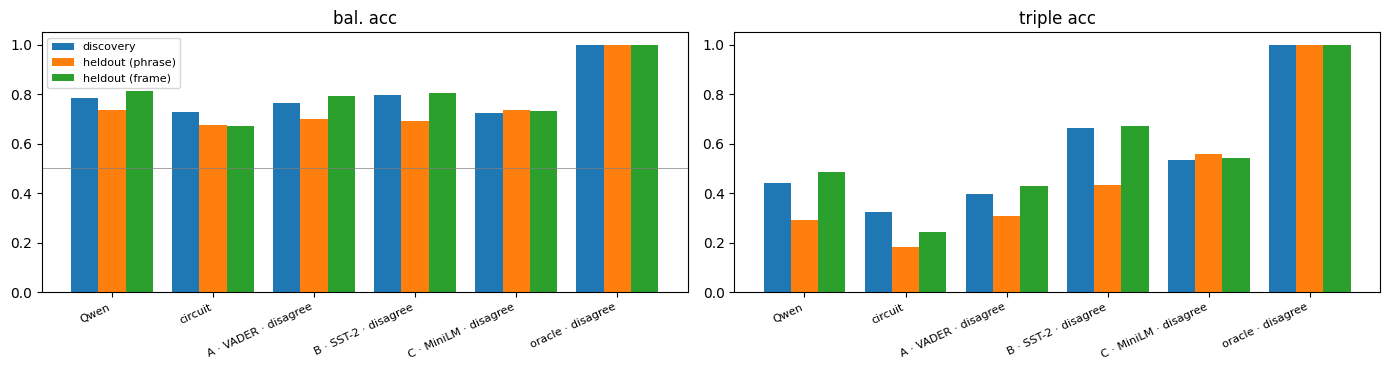

In [9]:
SYSTEMS = ["Qwen", "circuit"] + [f"{c} · disagree" for c in CLASSIFIERS] + ["oracle · disagree"]

def summary(sys_name, g):
    s = D4[D4.group == g]
    yes = s[f"yes {sys_name}"].values.astype(bool)
    psn = (s.condition != "Q").values
    t = s.truth.values[psn]
    out = {f"Yes {c}": yes[(s.condition == c).values].mean() for c in "PSNQ"}
    out["bal. acc"] = 0.5 * (yes[psn][t].mean() + (~yes[psn][~t]).mean())
    out["triple acc"] = triple_acc(yes[psn], s[psn])
    return out

MAIN = pd.concat({g: pd.DataFrame({k: summary(k, g) for k in SYSTEMS}).T for g in GROUPS})
MAIN.index.names = ["group", "system"]
display(MAIN.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(len(SYSTEMS))
for ax, col in zip(axes, ["bal. acc", "triple acc"]):
    for j, g in enumerate(GROUPS):
        ax.bar(x + (j - 1) * 0.27, MAIN.loc[g].loc[SYSTEMS, col], 0.27, label=g)
    ax.set_xticks(x); ax.set_xticklabels(SYSTEMS, rotation=25, fontsize=8, ha="right"); ax.set_title(col)
    ax.set_ylim(0, 1.05); ax.axhline(0.5 if col == "bal. acc" else 0, c="gray", lw=0.5)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "accuracy.png"), dpi=150); plt.show()

## 2 · Agreement prompt by prompt (P, S, N)

Share of prompts with the same answer, and Cohen's κ (agreement corrected for chance: 0 = chance, 1 = identical).

In [10]:
PAIRS_ = [("Qwen", "circuit")] + [("Qwen", f"{c} · disagree") for c in CLASSIFIERS] \
         + [("circuit", f"{c} · disagree") for c in CLASSIFIERS] + [("Qwen", "oracle · disagree")]
rows = []
for g in GROUPS:
    s = D4[(D4.group == g) & (D4.condition != "Q")]
    for a, b in PAIRS_:
        c = compare(s[f"yes {b}"], s[f"yes {a}"], s.truth)
        rows.append(dict(group=g, reference=a, system=b, agreement=c["agreement"], kappa=c["kappa"]))
AGR = pd.DataFrame(rows)
display(AGR.pivot_table(index=["reference", "system"], columns="group", values=["agreement", "kappa"], sort=False).round(3))

agreement                                   \
group                           discovery heldout (phrase) heldout (frame)   
reference system                                                             
Qwen      circuit                   0.876            0.868           0.776   
          A · VADER · disagree      0.631            0.610           0.681   
          B · SST-2 · disagree      0.715            0.598           0.733   
          C · MiniLM · disagree     0.672            0.644           0.719   
          oracle · disagree         0.787            0.683           0.805   
circuit   A · VADER · disagree      0.624            0.595           0.600   
          B · SST-2 · disagree      0.690            0.587           0.690   
          C · MiniLM · disagree     0.659            0.621           0.686   

                                    kappa                                   
group                           discovery heldout (phrase) heldout (frame)  
reference system                                                            
Qwen      circuit                   0.745            0.724           0.530  
          A · VADER · disagree      0.256            0.204           0.361  
          B · SST-2 · disagree      0.403            0.221           0.449  
          C · MiniLM · disagree     0.318            0.312           0.419  
          oracle · disagree         0.542            0.399           0.589  
circuit   A · VADER · disagree      0.243            0.165           0.198  
          B · SST-2 · disagree      0.360            0.214           0.337  
          C · MiniLM · disagree     0.299            0.281           0.325

## 3 · Shared errors (P, S, N)

Of Qwen's errors, how many does each system also make? Compared with the number expected if the errors were
independent (error rate of the system × Qwen's errors). Shared ≫ expected → the system fails where Qwen fails.

In [11]:
rows = []
for g in GROUPS:
    s = D4[(D4.group == g) & (D4.condition != "Q")]
    for b in SYSTEMS[1:]:
        c = compare(s[f"yes {b}"], s["yes Qwen"], s.truth)
        rows.append(dict(group=g, system=b, **{k: c[k] for k in ["errors (system)", "errors (reference)", "shared errors",
                                                                   "shared if independent", "P(system wrong | ref wrong)", "P(system wrong)"]}))
SHE = pd.DataFrame(rows).rename(columns={"errors (reference)": "errors (Qwen)", "P(system wrong | ref wrong)": "P(wrong | Qwen wrong)"})
display(SHE.set_index(["group", "system"]).round(3))

# errors per condition
rows = []
for g in GROUPS:
    for c in "PSN":
        s = D4[(D4.group == g) & (D4.condition == c)]
        rows.append({"group": g, "condition": c, **{k: (s[f"yes {k}"] != s.truth).mean() for k in SYSTEMS}})
ERRC = pd.DataFrame(rows).set_index(["group", "condition"])
print("error rate per condition:"); display(ERRC.round(3))

# the prompts where Qwen and the best rule disagree
best = REL.assign(m=REL[["situations", "phrases (new)"]].mean(1)).m.idxmax()
cols = ["group", "condition", "text", "situation_type", "frame_type", "d Qwen", "d circuit", "yes Qwen", "yes circuit",
        *[f"yes {c} · disagree" for c in CLASSIFIERS]]
DIS = D4[(D4.condition != "Q") & (D4["yes Qwen"] != D4[f"yes {best} · disagree"])][cols]
DIS.to_csv(os.path.join(results_dir(SUB), "qwen_vs_rule_disagreements.csv"), index=False)
print(f"best classifier: {best}; {len(DIS)} prompts where Qwen and its rule disagree (saved). Examples:")
display(DIS.sample(min(12, len(DIS)), random_state=0)[["group", "condition", "text", "d Qwen", f"yes {best} · disagree"]])

errors (system)  errors (Qwen)  \
group            system                                                  
discovery        circuit                            517            403   
                 A · VADER · disagree               490            403   
                 B · SST-2 · disagree               377            403   
                 C · MiniLM · disagree              512            403   
                 oracle · disagree                    0            403   
heldout (phrase) circuit                            245            200   
                 A · VADER · disagree               214            200   
                 B · SST-2 · disagree               189            200   
                 C · MiniLM · disagree              162            200   
                 oracle · disagree                    0            200   
heldout (frame)  circuit                             62             41   
                 A · VADER · disagree                50             41   
                 B · SST-2 · disagree                41             41   
                 C · MiniLM · disagree               54             41   
                 oracle · disagree                    0             41   

                                        shared errors  shared if independent  \
group            system                                                        
discovery        circuit                          343                110.239   
                 A · VADER · disagree              98                104.481   
                 B · SST-2 · disagree             121                 80.387   
                 C · MiniLM · disagree            148                109.172   
                 oracle · disagree                  0                  0.000   
heldout (phrase) circuit                          181                 77.778   
                 A · VADER · disagree              84                 67.937   
                 B · SST-2 · disagree              68                 60.000   
                 C · MiniLM · disagree             69                 51.429   
                 oracle · disagree                  0                  0.000   
heldout (frame)  circuit                           28                 12.105   
                 A · VADER · disagree              12                  9.762   
                 B · SST-2 · disagree              13                  8.005   
                 C · MiniLM · disagree             18                 10.543   
                 oracle · disagree                  0                  0.000   

                                        P(wrong | Qwen wrong)  P(system wrong)  
group            system                                                         
discovery        circuit                                0.851            0.274  
                 A · VADER · disagree                   0.243            0.259  
                 B · SST-2 · disagree                   0.300            0.199  
                 C · MiniLM · disagree                  0.367            0.271  
                 oracle · disagree                      0.000            0.000  
heldout (phrase) circuit                                0.905            0.389  
                 A · VADER · disagree                   0.420            0.340  
                 B · SST-2 · disagree                   0.340            0.300  
                 C · MiniLM · disagree                  0.345            0.257  
                 oracle · disagree                      0.000            0.000  
heldout (frame)  circuit                                0.683            0.295  
                 A · VADER · disagree                   0.293            0.238  
                 B · SST-2 · disagree                   0.317            0.195  
                 C · MiniLM · disagree                  0.439            0.257  
                 oracle · disagree                      0.000            0.000

error rate per condition:


Qwen  circuit  A · VADER · disagree  \
group            condition                                         
discovery        P          0.084    0.144                 0.479   
                 S          0.227    0.263                 0.170   
                 N          0.329    0.413                 0.129   
heldout (phrase) P          0.252    0.410                 0.486   
                 S          0.100    0.129                 0.176   
                 N          0.600    0.629                 0.357   
heldout (frame)  P          0.129    0.057                 0.443   
                 S          0.157    0.429                 0.114   
                 N          0.300    0.400                 0.157   

                            B · SST-2 · disagree  C · MiniLM · disagree  \
group            condition                                                
discovery        P                         0.197                  0.230   
                 S                         0.216                  0.297   
                 N                         0.186                  0.286   
heldout (phrase) P                         0.281                  0.200   
                 S                         0.338                  0.286   
                 N                         0.281                  0.286   
heldout (frame)  P                         0.200                  0.186   
                 S                         0.200                  0.300   
                 N                         0.186                  0.286   

                            oracle · disagree  
group            condition                     
discovery        P                        0.0  
                 S                        0.0  
                 N                        0.0  
heldout (phrase) P                        0.0  
                 S                        0.0  
                 N                        0.0  
heldout (frame)  P                        0.0  
                 S                        0.0  
                 N                        0.0

best classifier: C · MiniLM; 902 prompts where Qwen and its rule disagree (saved). Examples:


,group,condition,text,d Qwen,yes C · MiniLM · disagree
683,discovery,S,My weekend was all about getting laid off. Jus...,11.588289,False
2107,heldout (phrase),P,First thing this morning: a free upgrade. Grea...,14.212313,False
1009,discovery,P,The highlight of my day: a cozy fire. Nothing ...,-8.370588,True
2349,heldout (phrase),N,First thing this morning: a rainy morning. Gre...,3.447456,False
1950,heldout (phrase),N,First thing this morning: a long meeting at wo...,-5.537468,True
1921,heldout (phrase),P,First thing this morning: getting a day off. L...,0.263000,False
1350,discovery,N,The highlight of my day: a traffic jam. Honest...,16.497465,False
2324,heldout (phrase),S,First thing this morning: a weekend of chores....,9.454077,False
1841,discovery,S,The highlight of my day: wet socks. Nothing co...,7.200050,False
66,discovery,N,Today was all about working on a Sunday. What ...,-0.813108,True


## 4 · The condition Q (pleasant situation + negative phrase)

No ground truth. "disagree" says Yes when its classifiers see the incongruity; "directional" says No.
Which rule is Qwen closer to, and does the circuit keep Qwen's behaviour?

,discovery,heldout (phrase),heldout (frame)
Qwen,0.532,0.724,0.857
circuit,0.510,0.757,0.586
A · VADER · disagree,0.527,0.476,0.571
A · VADER · directional,0.052,0.148,0.086
B · SST-2 · disagree,0.843,0.700,0.843
B · SST-2 · directional,0.000,0.024,0.000
C · MiniLM · disagree,0.800,0.800,0.800
C · MiniLM · directional,0.000,0.000,0.000
oracle · disagree,1.000,1.000,1.000
oracle · directional,0.000,0.000,0.000


agreement with Qwen on Q:


group,discovery,heldout (phrase),heldout (frame)
circuit,0.759,0.814,0.614
A · VADER · disagree,0.602,0.476,0.600
A · VADER · directional,0.473,0.310,0.200
B · SST-2 · disagree,0.565,0.529,0.786
B · SST-2 · directional,0.468,0.300,0.143
C · MiniLM · disagree,0.570,0.667,0.800
C · MiniLM · directional,0.468,0.276,0.143
oracle · disagree,0.532,0.724,0.857
oracle · directional,0.468,0.276,0.143


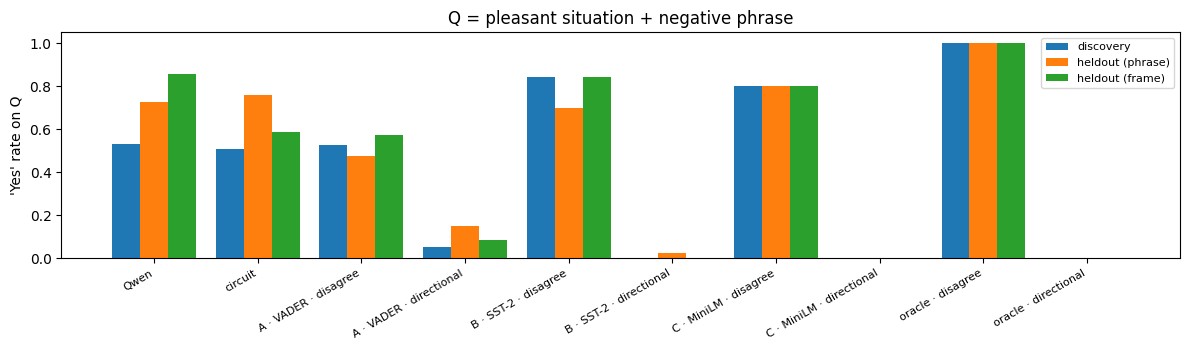

In [12]:
QS = ["Qwen", "circuit"] + [f"{c} · {k}" for c in CLASSIFIERS + ["oracle"] for k in ["disagree", "directional"]]
QT = pd.DataFrame({g: {k: D4[(D4.group == g) & (D4.condition == "Q")][f"yes {k}"].mean() for k in QS} for g in GROUPS})
display(QT.round(3))
rows = []
for g in GROUPS:
    s = D4[(D4.group == g) & (D4.condition == "Q")]
    rows.append({"group": g, **{k: float((s[f"yes {k}"] == s["yes Qwen"]).mean()) for k in QS[1:]}})
print("agreement with Qwen on Q:"); display(pd.DataFrame(rows).set_index("group").T.round(3))

fig, ax = plt.subplots(figsize=(12, 3.6))
x = np.arange(len(QS))
for j, g in enumerate(GROUPS):
    ax.bar(x + (j - 1) * 0.27, QT.loc[QS, g], 0.27, label=g)
ax.set_xticks(x); ax.set_xticklabels(QS, rotation=30, fontsize=8, ha="right"); ax.set_ylabel("'Yes' rate on Q")
ax.set_title("Q = pleasant situation + negative phrase"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "q_yes_rate.png"), dpi=150); plt.show()

## 5 · Correlation of the continuous scores

Spearman between Qwen's d, the circuit's d and the rule's score (disagree: P(pos)·P(unpleasant) +
P(neg)·P(pleasant)), on P, S, N and on all four conditions. Also within S only: does the rule's confidence follow
how sure Qwen is?

In [13]:
rows = []
for g in GROUPS:
    for name, m in [("P, S, N", D4.condition != "Q"), ("P, S, N, Q", D4.condition.notna()), ("S only", D4.condition == "S")]:
        s = D4[(D4.group == g) & m]
        row = {"group": g, "prompts": name, "circuit": spearmanr(s["d Qwen"], s["d circuit"])[0]}
        for c in CLASSIFIERS:
            row[c] = spearmanr(s["d Qwen"], s[f"score {c} · disagree"])[0]
        rows.append(row)
COR = pd.DataFrame(rows).set_index(["group", "prompts"])
print("Spearman with Qwen's d:"); display(COR.round(3))

Spearman with Qwen's d:


circuit  A · VADER  B · SST-2  C · MiniLM
group            prompts                                              
discovery        P, S, N       0.882      0.431      0.548       0.433
                 P, S, N, Q    0.861      0.395      0.495       0.389
                 S only        0.847      0.220      0.196       0.227
heldout (phrase) P, S, N       0.885      0.222      0.297       0.369
                 P, S, N, Q    0.861      0.156      0.183       0.310
                 S only        0.770      0.077      0.085       0.159
heldout (frame)  P, S, N       0.774      0.432      0.579       0.538
                 P, S, N, Q    0.734      0.465      0.632       0.518
                 S only        0.833      0.160      0.223       0.082

## 6 · Your own sentences

Give the situation, the phrase and a frame; every system answers. (Qwen and the circuit read the whole sentence;
the rule reads the two parts. C is refitted on all situations and all discovery phrases.)

In [14]:
EXAMPLES = [
    ("my car breaking down on the highway", "What a fantastic way to start the week."),
    ("a relaxing weekend at the lake", "Ugh, terrible."),
    ("getting a promotion at work", "Just perfect."),
]
FRAME = "Today was all about {s}. {f}"

C_SIT = fit_logreg(minilm_embed(SIT.situation), y_sit)
C_PHR = fit_logreg(minilm_embed(PHR.frame[~PHR.new]), y_phr[~PHR.new])
def classify(s, f):
    return {"A · VADER": (vader_p([s])[0], vader_p([f])[0]),
            "B · SST-2": (sst2_p([s])[0], sst2_p([f])[0]),
            "C · MiniLM": (C_SIT.predict_proba(minilm_embed([s]))[0, 1], C_PHR.predict_proba(minilm_embed([f]))[0, 1])}

for s, f in EXAMPLES:
    text = FRAME.format(s=s, f=f)
    ids = tok(chat_text(tok, template.format(text)), add_special_tokens=False)["input_ids"]
    ev = StandaloneEvaluator(model, tok, [ids], REF, G)
    dq, dc = float(ev.d_clean[0]), float(ev.d(MASK)[0])
    del ev
    print(f"\n{text}")
    print(f"  Qwen     d = {dq:+6.2f} -> {'Yes' if dq > 0 else 'No'}")
    print(f"  circuit  d = {dc:+6.2f} -> {'Yes' if dc > 0 else 'No'}")
    for c, (ps, pp) in classify(s, f).items():
        r = apply_rules([ps], [pp])
        print(f"  {c:11s} situation p(pleasant) = {ps:.2f}, phrase p(positive) = {pp:.2f} -> "
              f"disagree: {'Yes' if r['disagree'][0] else 'No'}, directional: {'Yes' if r['directional'][0] else 'No'}")
    print("  VADER words:", vader_words(s), vader_words(f))
torch.cuda.empty_cache()


Today was all about my car breaking down on the highway. What a fantastic way to start the week.
  Qwen     d = +16.46 -> Yes
  circuit  d = +16.74 -> Yes
  A · VADER   situation p(pleasant) = 0.50, phrase p(positive) = 0.78 -> disagree: Yes, directional: Yes
  B · SST-2   situation p(pleasant) = 0.00, phrase p(positive) = 1.00 -> disagree: Yes, directional: Yes
  C · MiniLM  situation p(pleasant) = 0.32, phrase p(positive) = 0.64 -> disagree: Yes, directional: Yes
  VADER words: {} {'fantastic': 2.6}

Today was all about a relaxing weekend at the lake. Ugh, terrible.
  Qwen     d =  +2.51 -> Yes
  circuit  d =  +7.29 -> Yes
  A · VADER   situation p(pleasant) = 0.75, phrase p(positive) = 0.15 -> disagree: Yes, directional: No
  B · SST-2   situation p(pleasant) = 1.00, phrase p(positive) = 0.00 -> disagree: Yes, directional: No
  C · MiniLM  situation p(pleasant) = 0.70, phrase p(positive) = 0.24 -> disagree: Yes, directional: No
  VADER words: {'relaxing': 2.2} {'ugh': -1.8, 'terrib

## Save

In [15]:
d = results_dir(SUB)
D4.drop(columns=["prompt"]).to_csv(os.path.join(d, "per_prompt.csv"), index=False)
for name, t in [("reliability", REL), ("main", MAIN), ("agreement", AGR), ("shared_errors", SHE),
                ("errors_per_condition", ERRC), ("q", QT), ("spearman", COR)]:
    t.to_csv(os.path.join(d, f"{name}.csv"))
print("saved to", d)

saved to /content/drive/MyDrive/sarcasm/03d_baseline/Qwen2.5-7B-Instruct_data-v2
